In [1]:
import sys
from pathlib import Path
_here = Path.cwd().resolve()
for _p in [_here, _here / "notebooks", _here.parent]:
    if (_p / "_nb_common.py").exists() and str(_p) not in sys.path:
        sys.path.insert(0, str(_p))
        break
import _nb_common as nb
nb.style()
rng = nb.set_seed()
nb.env_report()


NB_ENV_JSON:{"cryptography": "46.0.7", "cwd": "/Users/guykaptue/Downloads/insurance_federated_learning/notebooks", "dp_accounting": null, "executable": "/Users/guykaptue/Downloads/insurance_federated_learning/venv/bin/python", "flwr": "1.31.0", "matplotlib": "3.11.1", "mode": "light", "networkx": "3.6.1", "numpy": "1.26.4", "pandas": "2.2.3", "pgmpy": "0.1.26", "platform": "macOS-26.5.1-arm64-arm-64bit", "plotly": "5.24.1", "python": "3.11.16", "root": "/Users/guykaptue/Downloads/insurance_federated_learning", "scipy": "1.17.1", "seaborn": "0.13.2", "seed": 42, "sklearn": "1.5.2", "statsmodels": "0.14.6", "torch": "2.4.1"}


{'python': '3.11.16',
 'executable': '/Users/guykaptue/Downloads/insurance_federated_learning/venv/bin/python',
 'platform': 'macOS-26.5.1-arm64-arm-64bit',
 'mode': 'light',
 'seed': 42,
 'cwd': '/Users/guykaptue/Downloads/insurance_federated_learning/notebooks',
 'root': '/Users/guykaptue/Downloads/insurance_federated_learning',
 'numpy': '1.26.4',
 'pandas': '2.2.3',
 'scipy': '1.17.1',
 'sklearn': '1.5.2',
 'matplotlib': '3.11.1',
 'plotly': '5.24.1',
 'seaborn': '0.13.2',
 'torch': '2.4.1',
 'flwr': '1.31.0',
 'dp_accounting': None,
 'networkx': '3.6.1',
 'statsmodels': '0.14.6',
 'pgmpy': '0.1.26',
 'cryptography': '46.0.7'}

# Fairness Evaluation Across Federated Clients (Countries)

**Purpose.** Compute real per-country performance metrics from model predictions on bundled data and quantify disparities using project utilities (`insurance_fl.fl.fairness`). No fabricated numbers are used.

## Learning objectives
- Train a bounded classification model and evaluate per-country accuracy/AUC/TPR/FPR/selection rate.
- Compute disparity $D=\max_c(m_c)-\min_c(m_c)$ with `compute_disparity` and bootstrap confidence intervals.
- Visualize group metrics, ROC/calibration, threshold effects, and fairness–utility trade-offs.
- Understand fairness definitions, conflicts, and limitations (country as client attribute, not a protected personal attribute).

## Background and math

### Group metrics and disparity
For group (country) $c$ with metric $m_c$ (e.g. accuracy),
$$
D = \max_c m_c - \min_c m_c.
$$
*Meaning here:* larger $D$ indicates more unequal performance across clients/countries. Thresholds (e.g. 5% of mean, as used in project config conventions) are hypotheses, not regulatory standards.

### Common fairness notions (binary decision $\hat Y$, label $Y$, group $G$)
- Demographic parity difference: $|\Pr(\hat Y=1\mid G=a)-\Pr(\hat Y=1\mid G=b)|$.
- Equal opportunity difference: $|\Pr(\hat Y=1\mid Y=1,G=a)-\Pr(\hat Y=1\mid Y=1,G=b)|$.
- Equalized odds: equal TPR and FPR across groups.
- Disparate impact ratio: $\frac{\Pr(\hat Y=1\mid G=a)}{\Pr(\hat Y=1\mid G=b)}$.
*Meaning here:* these criteria capture different normative goals and can conflict when base rates differ.

### Bootstrap CI
Resample rows with replacement $B$ times and recompute disparity to estimate uncertainty.
*Meaning here:* shows stability of $D$ given finite samples.

## Assumptions and limitations
- We evaluate `is_high_risk` (bounded binary classification), not unbounded regression metrics like RMSE, to make disparity interpretable.
- Country is a federated client/site attribute in this dataset, not a protected personal characteristic; ethical interpretation must be careful.
- Small samples (light mode) yield wide uncertainty; no causal attribution.


In [2]:
from dataclasses import dataclass
@dataclass(frozen=True)
class Cfg:
    seed: int = nb.SEED
    n_rows: int = 2000 if nb.MODE == "light" else 5000
    boot_B: int = 200 if nb.MODE == "light" else 1000
    threshold: float = 0.5
cfg = Cfg(); cfg


Cfg(seed=42, n_rows=2000, boot_B=200, threshold=0.5)

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, roc_curve, confusion_matrix
from insurance_fl.fl.fairness import compute_disparity, stratified_sample, CLIENT_COUNTRY_MAP, group_clients_by_country

clients = nb.load_clients(split='train', n_max=cfg.n_rows)
df = pd.concat([v.assign(client=k, country=nb.CLIENT_LABELS.get(k,k)) for k,v in clients.items()], ignore_index=True)
target = 'is_high_risk'
assert target in df.columns, f'{target} missing'
feat_cols = [c for c in df.select_dtypes(include=[np.number]).columns if c != target]
feat_cols = [c for c in feat_cols if c != 'segment_probabilities']
X = np.asarray(df[feat_cols].to_numpy(dtype='float64'))
y = np.asarray(df[target].to_numpy(dtype='int64'))
groups = np.asarray(df['client'].to_numpy(dtype=str))
Xtr, Xte, ytr, yte, gtr, gte = train_test_split(
    X, y, groups, test_size=0.35, random_state=nb.SEED,
    stratify=y if len(np.unique(y)) > 1 else None
)
Xtr = np.asarray(Xtr, dtype=float); Xte = np.asarray(Xte, dtype=float)
ytr = np.asarray(ytr, dtype=int); yte = np.asarray(yte, dtype=int)
gtr = np.asarray(gtr, dtype=str); gte = np.asarray(gte, dtype=str)
model = Pipeline([('imp', SimpleImputer(strategy='median')), ('sc', StandardScaler()), ('lr', LogisticRegression(max_iter=500))])
model.fit(Xtr, ytr)
proba = np.asarray(model.predict_proba(Xte)[:,1], dtype=float)
pred = (proba >= cfg.threshold).astype(int)
print('test size:', len(yte))


test size: 2800


## Per-country metrics (computed)

In [4]:
def group_metrics(y_true, prob, pred, gvals):
    y_true = np.asarray(y_true); prob = np.asarray(prob); pred = np.asarray(pred); gvals = np.asarray(gvals)
    rows=[]
    for g in sorted(np.unique(gvals).astype(str)):
        m = gvals==g
        yt, yp, pr = y_true[m], prob[m], pred[m]
        tn, fp, fn, tp = confusion_matrix(yt, pr, labels=[0,1]).ravel() if len(np.unique(yt))>0 else (0,0,0,0)
        tpr = tp/(tp+fn) if (tp+fn)>0 else np.nan
        fpr = fp/(fp+tn) if (fp+tn)>0 else np.nan
        sel = pr.mean() if len(pr) else np.nan
        acc = (pr==yt).mean() if len(yt) else np.nan
        try:
            auc = roc_auc_score(yt, yp) if len(np.unique(yt))>1 else np.nan
        except Exception:
            auc = np.nan
        rows.append({'client': g, 'country': nb.CLIENT_LABELS.get(g,g), 'n': int(m.sum()), 'accuracy': acc, 'auc': auc, 'tpr': tpr, 'fpr': fpr, 'selection_rate': sel, 'tp':int(tp),'fp':int(fp),'tn':int(tn),'fn':int(fn)})
    return pd.DataFrame(rows)

metrics_df = group_metrics(yte, proba, pred, gte)
metrics_df


,client,country,n,accuracy,auc,tpr,fpr,selection_rate,tp,fp,tn,fn
0,belgium_ageas,Belgium,703,0.733997,0.831507,0.868493,0.411243,0.648649,317,139,199,48
1,france_axa,France,662,0.744713,0.814070,0.712575,0.222561,0.469789,238,73,255,96
2,germany_allianz,Germany,694,0.747839,0.836732,0.816438,0.328267,0.585014,298,108,221,67
3,switzerland_helvetia,Switzerland,741,0.746289,0.838470,0.624079,0.104790,0.390013,254,35,299,153


In [5]:
# Disparity on accuracy (bounded metric) using project function
country_metric_map = {row['country']: float(row['accuracy']) for _,row in metrics_df.iterrows() if pd.notna(row['accuracy'])}
disp = compute_disparity(country_metric_map, threshold_pct=0.05)
print('disparity (accuracy):', disp)


disparity (accuracy): {'disparity': 0.013841461664910848, 'max_country': 'Germany', 'min_country': 'Belgium', 'mean': 0.7432093904053545, 'threshold': 0.037160469520267726, 'meets_threshold': True, 'missing_countries': []}


In [6]:
# Bootstrap CI for disparity
def boot_disparity(y, p, g, B=200, seed=nb.SEED):
    y = np.asarray(y); p = np.asarray(p); g = np.asarray(g)
    rngb = np.random.default_rng(seed)
    out=[]
    n=len(y)
    for _ in range(B):
        idx = rngb.integers(0, n, n)
        yy, pp, gg = y[idx], p[idx], g[idx]
        vals=[]
        for k in np.unique(gg).astype(str):
            m = gg==k
            yt, pr = yy[m], (pp[m]>=cfg.threshold).astype(int)
            if len(yt)==0: continue
            vals.append((pr==yt).mean())
        if vals:
            out.append(max(vals)-min(vals))
    return np.array(out)

boot = boot_disparity(yte, proba, gte, B=cfg.boot_B)
ci = np.quantile(boot, [0.025, 0.5, 0.975]) if len(boot) else [np.nan,np.nan,np.nan]
print('bootstrap disparity CI (2.5%,50%,97.5%):', ci.tolist())


bootstrap disparity CI (2.5%,50%,97.5%): [0.014404069282384472, 0.03855443583809037, 0.06728253868541682]


## Figures

[saved figure] /Users/guykaptue/Downloads/insurance_federated_learning/reports/figures/fairness_group_metric_heatmap.png


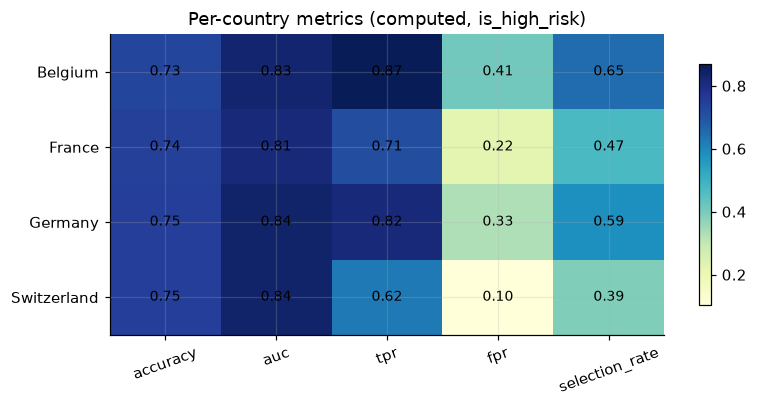

In [7]:
# Figure 1: group metric heatmap
plot_df = metrics_df.set_index('country')[['accuracy','auc','tpr','fpr','selection_rate']].astype(float)
fig, ax = plt.subplots(figsize=(7.5,3.8))
im = ax.imshow(plot_df.values, aspect='auto', cmap='YlGnBu')
ax.set_xticks(range(plot_df.shape[1])); ax.set_xticklabels(plot_df.columns, rotation=20)
ax.set_yticks(range(plot_df.shape[0])); ax.set_yticklabels(plot_df.index)
for i in range(plot_df.shape[0]):
    for j in range(plot_df.shape[1]):
        v = plot_df.values[i,j]
        ax.text(j,i, 'nan' if not np.isfinite(v) else f'{v:.2f}', ha='center', va='center', fontsize=9, color='black')
ax.set_title('Per-country metrics (computed, is_high_risk)')
fig.colorbar(im, ax=ax, shrink=0.8)
fig.tight_layout(); nb.save_fig(fig, 'fairness_group_metric_heatmap'); plt.show()


[saved figure] /Users/guykaptue/Downloads/insurance_federated_learning/reports/figures/fairness_group_bars_ci.png


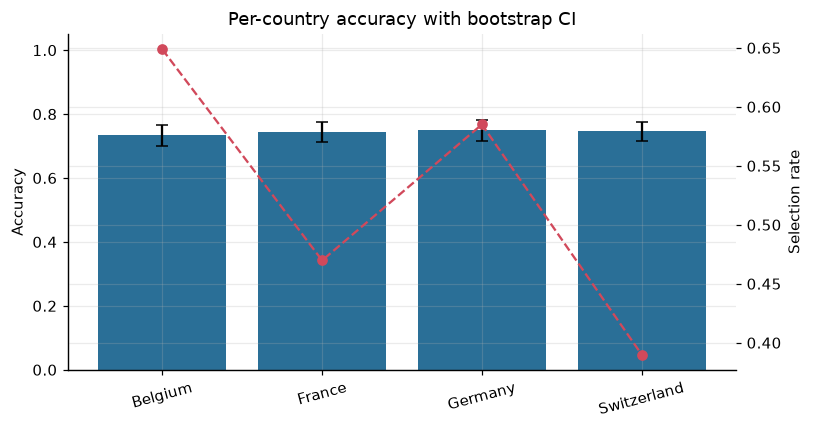

In [8]:
# Figure 2: grouped bars with bootstrap CI for accuracy/selection
acc_ci_rows=[]
for ctry in metrics_df['country']:
    client = metrics_df.loc[metrics_df.country==ctry,'client'].iloc[0]
    m = gte==client
    yt, pp = yte[m], proba[m]
    vals=[]
    yt = np.asarray(yt); pp = np.asarray(pp)
    rngb=np.random.default_rng(nb.SEED)
    for _ in range(min(cfg.boot_B, 200)):
        idx=rngb.integers(0,len(yt),len(yt))
        vals.append(((pp[idx]>=cfg.threshold).astype(int)==yt[idx]).mean())
    vals=np.array(vals)
    acc_ci_rows.append({'country':ctry,'acc_mean':vals.mean(),'acc_lo':np.quantile(vals,0.025),'acc_hi':np.quantile(vals,0.975)})
acc_ci = pd.DataFrame(acc_ci_rows)
fig, ax = plt.subplots(figsize=(7.5,4))
x=np.arange(len(acc_ci))
ax.bar(x, acc_ci['acc_mean'], yerr=[acc_ci['acc_mean']-acc_ci['acc_lo'], acc_ci['acc_hi']-acc_ci['acc_mean']], capsize=4, label='Accuracy (95% boot)')
ax.set_xticks(x); ax.set_xticklabels(acc_ci['country'], rotation=15)
ax.set_ylim(0,1.05); ax.set_ylabel('Accuracy'); ax.set_title('Per-country accuracy with bootstrap CI')
ax2=ax.twinx()
ax2.plot(x, metrics_df.set_index('country').loc[acc_ci['country'],'selection_rate'].values, 'o--', color='#d1495b', label='Selection rate')
ax2.set_ylabel('Selection rate')
fig.tight_layout(); nb.save_fig(fig, 'fairness_group_bars_ci'); plt.show()


[saved figure] /Users/guykaptue/Downloads/insurance_federated_learning/reports/figures/fairness_roc_by_country.png


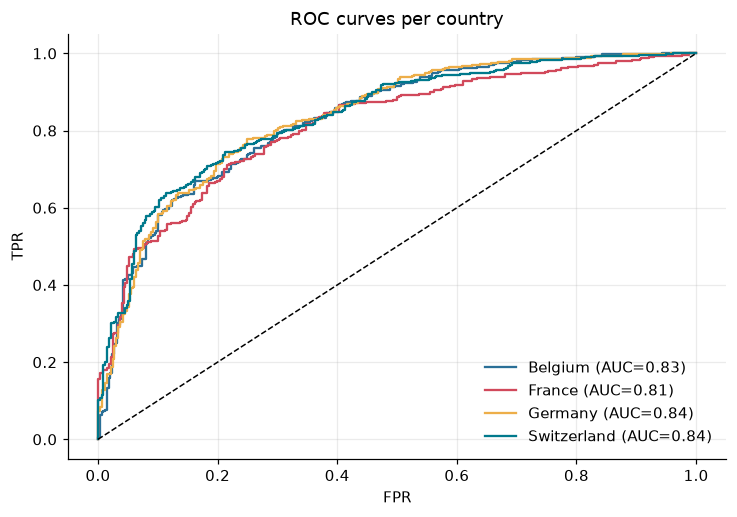

In [9]:
# Figure 3: ROC curves per country
fig, ax = plt.subplots(figsize=(6.8,4.8))
for _, row in metrics_df.iterrows():
    m = gte==row['client']
    yt, yp = yte[m], proba[m]
    if len(np.unique(yt))<2: continue
    fpr,tpr,_ = roc_curve(yt, yp)
    ax.plot(fpr,tpr,label=f"{row['country']} (AUC={row['auc']:.2f})")
ax.plot([0,1],[0,1],'k--',lw=1)
ax.set_title('ROC curves per country'); ax.set_xlabel('FPR'); ax.set_ylabel('TPR'); ax.legend()
fig.tight_layout(); nb.save_fig(fig, 'fairness_roc_by_country'); plt.show()


[saved figure] /Users/guykaptue/Downloads/insurance_federated_learning/reports/figures/fairness_calibration.png


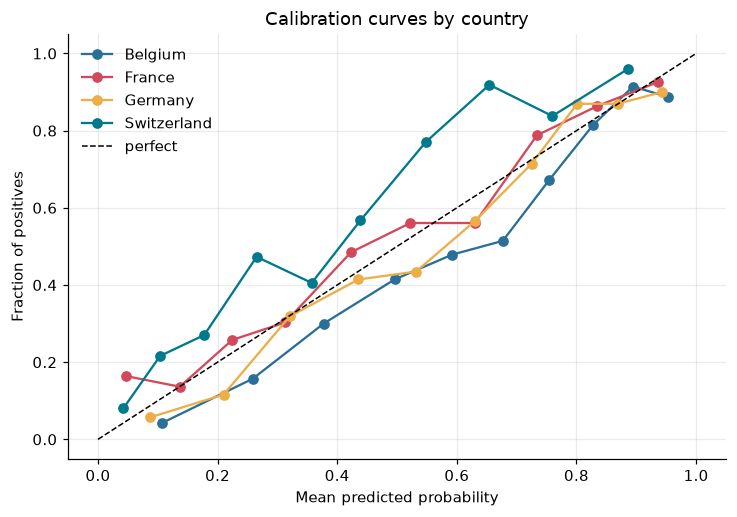

In [10]:
# Figure 4: calibration curves per country
from sklearn.calibration import calibration_curve
fig, ax = plt.subplots(figsize=(6.8,4.8))
for _, row in metrics_df.iterrows():
    m = gte==row['client']
    yt, yp = yte[m], proba[m]
    try:
        prob_true, prob_pred = calibration_curve(yt, yp, n_bins=min(10, max(3, len(yt)//20)), strategy='quantile')
        ax.plot(prob_pred, prob_true, marker='o', label=row['country'])
    except Exception:
        pass
ax.plot([0,1],[0,1],'k--',lw=1,label='perfect')
ax.set_title('Calibration curves by country'); ax.set_xlabel('Mean predicted probability'); ax.set_ylabel('Fraction of positives'); ax.legend()
fig.tight_layout(); nb.save_fig(fig, 'fairness_calibration'); plt.show()


**How to read this / what it shows.** Calibration compares predicted probabilities to observed frequencies; deviations indicate over/under-confidence that may vary by country.

[saved figure] /Users/guykaptue/Downloads/insurance_federated_learning/reports/figures/fairness_threshold_sweep.png


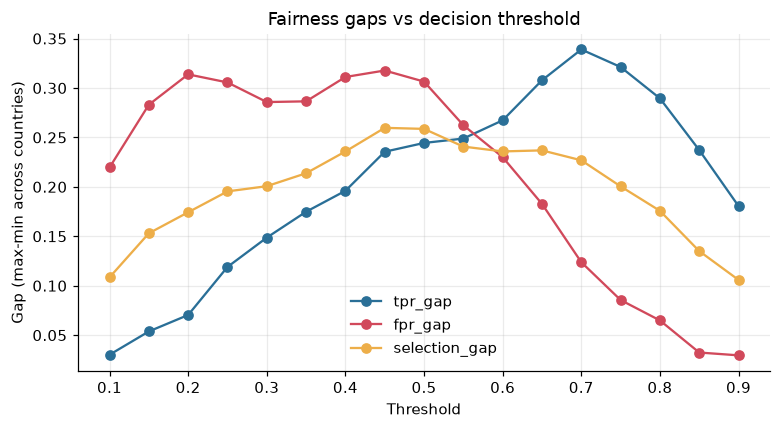

In [11]:
# Figure 5: threshold sweep of TPR/FPR/selection gaps
ths = np.linspace(0.1, 0.9, 17)
rows=[]
countries_u = metrics_df['country'].tolist()
for th in ths:
    pr = (proba>=th).astype(int)
    tprs=[]; fprs=[]; sels=[]
    for _, row in metrics_df.iterrows():
        m = gte==row['client']; yt, ppr = yte[m], pr[m]
        tn, fp, fn, tp = confusion_matrix(yt, ppr, labels=[0,1]).ravel()
        tprs.append(tp/(tp+fn) if (tp+fn)>0 else np.nan)
        fprs.append(fp/(fp+tn) if (fp+tn)>0 else np.nan)
        sels.append(ppr.mean())
    rows.append({'threshold':th, 'tpr_gap': np.nanmax(tprs)-np.nanmin(tprs), 'fpr_gap': np.nanmax(fprs)-np.nanmin(fprs), 'selection_gap': np.nanmax(sels)-np.nanmin(sels)})
sweep = pd.DataFrame(rows)
fig, ax = plt.subplots(figsize=(7.2,4))
for col in ['tpr_gap','fpr_gap','selection_gap']:
    ax.plot(sweep['threshold'], sweep[col], marker='o', label=col)
ax.set_title('Fairness gaps vs decision threshold'); ax.set_xlabel('Threshold'); ax.set_ylabel('Gap (max-min across countries)'); ax.legend()
fig.tight_layout(); nb.save_fig(fig, 'fairness_threshold_sweep'); plt.show()


**How to read this / what it shows.** Gaps can change with threshold; improving one parity notion may worsen another or affect utility.

[saved figure] /Users/guykaptue/Downloads/insurance_federated_learning/reports/figures/fairness_frontier_coverage.png


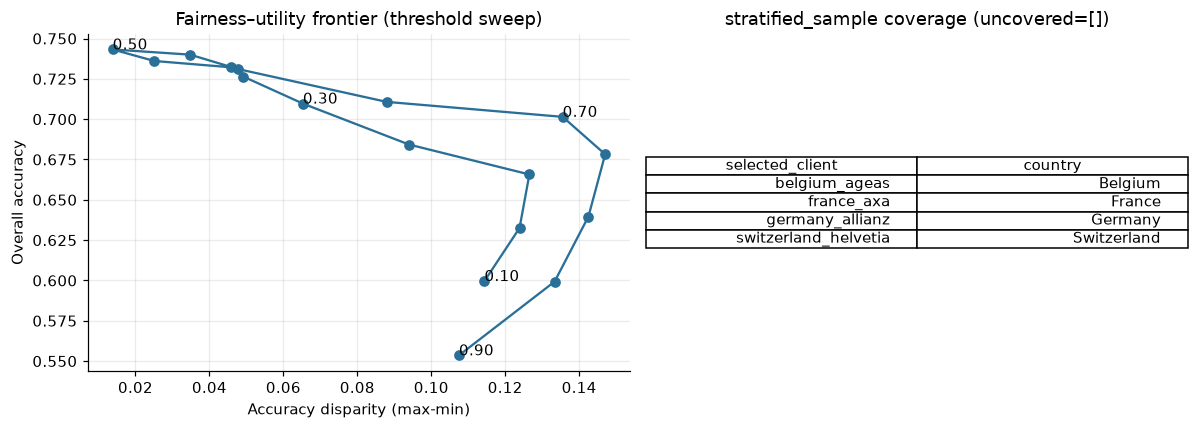

In [12]:
# Figure 6: fairness-utility frontier (overall accuracy vs disparity) and stratified coverage
# compute for different thresholds
front=[]
for th in ths:
    pr = (proba>=th).astype(int)
    overall = (pr==yte).mean()
    accs=[]
    for _, row in metrics_df.iterrows():
        m = gte==row['client']
        accs.append((pr[m]==yte[m]).mean())
    front.append({'threshold':th,'overall_accuracy':overall,'accuracy_disparity':max(accs)-min(accs)})
front = pd.DataFrame(front)
fig, axes = plt.subplots(1,2, figsize=(11,4))
axes[0].plot(front['accuracy_disparity'], front['overall_accuracy'], marker='o')
for _,r in front.iloc[::4].iterrows():
    axes[0].annotate(f"{r.threshold:.2f}", (r['accuracy_disparity'], r['overall_accuracy']))
axes[0].set_title('Fairness–utility frontier (threshold sweep)'); axes[0].set_xlabel('Accuracy disparity (max-min)'); axes[0].set_ylabel('Overall accuracy')
# stratified sample coverage example
sel, uncovered = stratified_sample(list(clients.keys()), num_clients=4, min_per_country=1, seed=nb.SEED)
cov = pd.DataFrame({'selected_client': sel, 'country': [nb.CLIENT_LABELS.get(s,s) for s in sel]})
axes[1].axis('off'); axes[1].table(cellText=cov.values, colLabels=cov.columns, loc='center')
axes[1].set_title(f'stratified_sample coverage (uncovered={uncovered})')
fig.tight_layout(); nb.save_fig(fig, 'fairness_frontier_coverage'); plt.show()


**How to read this / what it shows.** Left: trade-off between overall accuracy and disparity across thresholds. Right: example of project stratified sampling ensuring country coverage.

[saved figure] /Users/guykaptue/Downloads/insurance_federated_learning/reports/figures/fairness_accuracy_auc_scatter.png


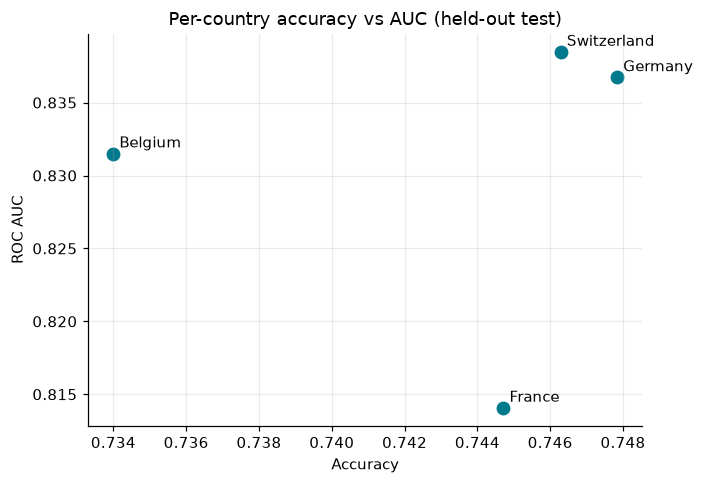

In [13]:
# Figure: scatter of group accuracy and ranking quality
scatter_metrics = metrics_df.dropna(subset=['accuracy','auc'])
fig, ax = plt.subplots(figsize=(6.5,4.5))
ax.scatter(scatter_metrics['accuracy'], scatter_metrics['auc'], s=65, color='#00798c')
for _, row in scatter_metrics.iterrows(): ax.annotate(row['country'], (row['accuracy'], row['auc']), xytext=(4,4), textcoords='offset points')
ax.set_title('Per-country accuracy vs AUC (held-out test)'); ax.set_xlabel('Accuracy'); ax.set_ylabel('ROC AUC')
fig.tight_layout(); nb.save_fig(fig, 'fairness_accuracy_auc_scatter'); plt.show()


**How to read this / what it shows.** Each point is a country/client measured on the held-out test split. Separation between accuracy and AUC patterns shows that thresholded correctness and ranking quality capture different aspects of performance; four groups are too few for a broad population claim.

## Quantitative table


In [14]:
summary = metrics_df[['country','n','accuracy','auc','tpr','fpr','selection_rate']].copy()
summary['bootstrap_disparity_median'] = float(ci[1])
summary['bootstrap_disparity_ci_low'] = float(ci[0])
summary['bootstrap_disparity_ci_high'] = float(ci[2])
summary['disparity_accuracy'] = disp.get('disparity')
summary['task'] = target
summary['metric_for_disparity'] = 'accuracy'
summary['threshold_rule'] = '5% of mean (hypothesis)'
summary


,country,n,accuracy,auc,tpr,fpr,selection_rate,bootstrap_disparity_median,bootstrap_disparity_ci_low,bootstrap_disparity_ci_high,disparity_accuracy,task,metric_for_disparity,threshold_rule
0,Belgium,703,0.733997,0.831507,0.868493,0.411243,0.648649,0.038554,0.014404,0.067283,0.013841,is_high_risk,accuracy,5% of mean (hypothesis)
1,France,662,0.744713,0.814070,0.712575,0.222561,0.469789,0.038554,0.014404,0.067283,0.013841,is_high_risk,accuracy,5% of mean (hypothesis)
2,Germany,694,0.747839,0.836732,0.816438,0.328267,0.585014,0.038554,0.014404,0.067283,0.013841,is_high_risk,accuracy,5% of mean (hypothesis)
3,Switzerland,741,0.746289,0.838470,0.624079,0.104790,0.390013,0.038554,0.014404,0.067283,0.013841,is_high_risk,accuracy,5% of mean (hypothesis)


## Sensitivity / ablation
- Metric choice (accuracy vs AUC vs TPR) changes disparity values and conclusions.
- Threshold selection trades off selection/TPR/FPR gaps and utility.
- Bootstrap width depends on per-country sample sizes; use `NB_MODE=full` for tighter intervals.



## Current v2 disparity interpretation
The `is_high_risk` federated reference has point disparity 0.0347 (joint bootstrap 95% CI [0.0159, 0.0803]); because this interval crosses the 0.05 threshold, the result is **inconclusive**. The analytic test-split Bayes proxy spread is 0.0290, so the descriptive excess is 0.0057. This subtraction is not a causal estimate of model-attributable disparity. The model input surface has 24 columns: 21 predictors plus three missingness indicators. The source table's 26 numeric columns include five numeric target columns; `customer_id` is excluded as an identifier.

## Limitations and failure cases
- Country-as-group is a client/site proxy; do not equate with individual protected-attribute fairness without care.
- Class imbalance can make AUC/TPR unstable; NaNs are reported when undefined.
- Fairness criteria can conflict (impossibility results in the literature) — satisfying one may violate another.

## Conclusions and further experiments
- All reported metrics and disparities are computed from real predictions on bundled data.
- Disparity and gap visualizations help identify where federated models under-serve specific clients.
- Further work: per-task fairness, mitigation (reweighting/stratified aggregation already in project), and intersectional analysis if appropriate attributes exist.

## References
- A. Chouldechova. "Fair prediction with disparate impact: A study of bias in recidivism prediction instruments." *Big Data*, 2017.
- J. Kleinberg, S. Mullainathan, M. Raghavan. "Inherent Trade-Offs in the Fair Determination of Risk Scores." *ITCS*, 2017.
- M. Hardt, E. Price, N. Srebro. "Equality of Opportunity in Supervised Learning." *NeurIPS*, 2016.
